# Análise Exploratória de Dados — Customer Churn

Este notebook realiza a investigação inicial do conjunto de dados de clientes de uma empresa de telecomunicações. O objetivo é compreender a estrutura e a qualidade dos dados, identificar possíveis riscos para a modelagem e analisar a distribuição da variável alvo de churn.

Nesta etapa, os problemas encontrados serão diagnosticados e documentados. A remoção de colunas, a imputação de valores ausentes e as demais transformações serão realizadas posteriormente, na etapa de preparação dos dados.

## 1. Importações

In [146]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

import seaborn as sns

## 2. Investigação inicial do dataset

### 2.1. Leitura do dataset bruto

O arquivo original é carregado em formato Excel. Inicialmente, são verificadas as planilhas disponíveis e realizada a leitura da planilha que contém os dados de churn.

In [147]:
xlsx_path = Path("../data/raw/Telco_customer_churn.xlsx")

excel = pd.ExcelFile(xlsx_path)
excel.sheet_names

['Telco_Churn']

In [148]:
df = pd.read_excel(xlsx_path, sheet_name="Telco_Churn")

display(df.head())

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


In [149]:
print(f"Linhas: {df.shape[0]:,}")
print(f"Colunas: {df.shape[1]}")

df.info()

Linhas: 7,043
Colunas: 33
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   str    
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   str    
 3   State              7043 non-null   str    
 4   City               7043 non-null   str    
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   str    
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   str    
 10  Senior Citizen     7043 non-null   str    
 11  Partner            7043 non-null   str    
 12  Dependents         7043 non-null   str    
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   str    
 15  Multiple Lines     7043 non-null   str    
 16  Internet 

### 2.2. Conversão para Parquet

A variável `Total Charges` é convertida para o tipo numérico. Valores que não puderem ser convertidos, como espaços em branco existentes no arquivo original, serão representados como `NaN`. Esses casos serão investigados na seção de qualidade dos dados.

O dataset é salvo em Parquet para tornar as próximas leituras mais rápidas e preservar os tipos das colunas.

In [150]:
df["Total Charges"] = pd.to_numeric(
    df["Total Charges"],
    errors="coerce",
)

processed_path = Path("../data/processed/dataset.parquet")
processed_path.parent.mkdir(parents=True, exist_ok=True)

df.to_parquet(processed_path, index=False)

In [151]:
df = pd.read_parquet(processed_path)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   str    
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   str    
 3   State              7043 non-null   str    
 4   City               7043 non-null   str    
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   str    
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   str    
 10  Senior Citizen     7043 non-null   str    
 11  Partner            7043 non-null   str    
 12  Dependents         7043 non-null   str    
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   str    
 15  Multiple Lines     7043 non-null   str    
 16  Internet Service   7043 non-null   

## 3. Visão geral do dataset

### 3.1. Dimensões do dataset

In [152]:
n_rows, n_cols = df.shape

print(f"Número de registros: {n_rows:,}")
print(f"Número de variáveis: {n_cols}")

Número de registros: 7,043
Número de variáveis: 33


O dataset possui **7.043 registros e 33 variáveis**, representando as informações disponíveis para a análise e para a posterior construção dos modelos de Machine Learning.

### 3.2. Visualização inicial

Além dos primeiros registros, é apresentada uma amostra aleatória. Isso evita formar uma impressão do dataset baseada somente na ordenação original das linhas.

In [153]:
display(df.head())
display(df.sample(5, random_state=42))

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Month-to-month,Yes,Electronic check,99.65,820.50,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.30,Yes,1,89,5340,Competitor had better devices


,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
185,2189-WWOEW,1,United States,California,Keene,93531,"35.214982, -118.59049",35.214982,-118.590490,Female,...,Month-to-month,Yes,Bank transfer (automatic),85.9,1269.55,Yes,1,96,3579,Don't know
2715,2446-ZKVAF,1,United States,California,Stockton,95207,"38.002125, -121.324979",38.002125,-121.324979,Male,...,Month-to-month,No,Credit card (automatic),56.8,1074.65,No,0,59,5558,NaN
3825,4986-MXSFP,1,United States,California,San Leandro,94579,"37.687264, -122.15728",37.687264,-122.157280,Female,...,Month-to-month,Yes,Mailed check,20.0,40.90,No,0,39,2237,NaN
1807,5868-YWPDW,1,United States,California,Sherman Oaks,91423,"34.146957, -118.432138",34.146957,-118.432138,Male,...,Month-to-month,Yes,Electronic check,84.2,519.15,Yes,1,72,5834,Limited range of services
132,9412-GHEEC,1,United States,California,Murrieta,92563,"33.581045, -117.14719",33.581045,-117.147190,Male,...,Month-to-month,No,Bank transfer (automatic),104.8,4131.95,Yes,1,88,3492,Service dissatisfaction


### 3.3. Variáveis disponíveis

In [154]:
df.columns.tolist()

['CustomerID',
 'Count',
 'Country',
 'State',
 'City',
 'Zip Code',
 'Lat Long',
 'Latitude',
 'Longitude',
 'Gender',
 'Senior Citizen',
 'Partner',
 'Dependents',
 'Tenure Months',
 'Phone Service',
 'Multiple Lines',
 'Internet Service',
 'Online Security',
 'Online Backup',
 'Device Protection',
 'Tech Support',
 'Streaming TV',
 'Streaming Movies',
 'Contract',
 'Paperless Billing',
 'Payment Method',
 'Monthly Charges',
 'Total Charges',
 'Churn Label',
 'Churn Value',
 'Churn Score',
 'CLTV',
 'Churn Reason']

### 3.4. Resumo estatístico inicial

O resumo numérico permite observar medidas de posição e dispersão. Já o resumo das variáveis categóricas mostra a quantidade de categorias, a categoria mais frequente e sua frequência.

In [155]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Count,7043.0,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000
Zip Code,7043.0,93521.964646,1865.794555,90001.000000,92102.000000,93552.000000,95351.000000,96161.000000
Latitude,7043.0,36.282441,2.455723,32.555828,34.030915,36.391777,38.224869,41.962127
Longitude,7043.0,-119.798880,2.157889,-124.301372,-121.815412,-119.730885,-118.043237,-114.192901
Tenure Months,7043.0,32.371149,24.559481,0.000000,9.000000,29.000000,55.000000,72.000000
Monthly Charges,7043.0,64.761692,30.090047,18.250000,35.500000,70.350000,89.850000,118.750000
Total Charges,7032.0,2283.300441,2266.771362,18.800000,401.450000,1397.475000,3794.737500,8684.800000
Churn Value,7043.0,0.265370,0.441561,0.000000,0.000000,0.000000,1.000000,1.000000
Churn Score,7043.0,58.699418,21.525131,5.000000,40.000000,61.000000,75.000000,100.000000
CLTV,7043.0,4400.295755,1183.057152,2003.000000,3469.000000,4527.000000,5380.500000,6500.000000


In [156]:
df.describe(include=["object", "string"]).T

,count,unique,top,freq
CustomerID,7043,7043,3668-QPYBK,1
Country,7043,1,United States,7043
State,7043,1,California,7043
City,7043,1129,Los Angeles,305
Lat Long,7043,1652,"33.964131, -118.272783",5
Gender,7043,2,Male,3555
Senior Citizen,7043,2,No,5901
Partner,7043,2,No,3641
Dependents,7043,2,No,5416
Phone Service,7043,2,Yes,6361


## 4. Qualidade dos dados

Antes das análises estatísticas e da construção dos modelos, é necessário avaliar a qualidade dos dados. Nesta etapa são investigados os tipos das variáveis, valores ausentes, duplicidades, colunas constantes, possíveis redundâncias e riscos de vazamento da variável alvo.

### 4.1. Tipos das variáveis

In [157]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   str    
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   str    
 3   State              7043 non-null   str    
 4   City               7043 non-null   str    
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   str    
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   str    
 10  Senior Citizen     7043 non-null   str    
 11  Partner            7043 non-null   str    
 12  Dependents         7043 non-null   str    
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   str    
 15  Multiple Lines     7043 non-null   str    
 16  Internet Service   7043 non-null   

In [158]:
types = pd.DataFrame({
    "Tipo": df.dtypes.astype(str),
    "Valores únicos": df.nunique(dropna=False),
})

display(types)

,Tipo,Valores únicos
CustomerID,str,7043
Count,int64,1
Country,str,1
State,str,1
City,str,1129
Zip Code,int64,1652
Lat Long,str,1652
Latitude,float64,1652
Longitude,float64,1651
Gender,str,2


O tipo técnico utilizado pelo Pandas nem sempre representa o papel conceitual da variável. Por exemplo, `Zip Code` é armazenada como número inteiro, mas representa um código geográfico, enquanto `Churn Value` é numérica e binária. Essa distinção será considerada no preprocessing.

### 4.2. Valores ausentes

In [159]:
missing = pd.DataFrame({
    "Quantidade": df.isna().sum(),
    "Percentual (%)": (df.isna().mean() * 100).round(2),
})

display(missing.sort_values("Quantidade", ascending=False))

,Quantidade,Percentual (%)
Churn Reason,5174,73.46
Total Charges,11,0.16
CustomerID,0,0.00
Count,0,0.00
Country,0,0.00
Zip Code,0,0.00
Lat Long,0,0.00
State,0,0.00
City,0,0.00
Gender,0,0.00


#### 4.2.1. Investigação de `Total Charges`

In [160]:
total_charges_missing = df.loc[
    df["Total Charges"].isna(),
    [
        "CustomerID",
        "Tenure Months",
        "Monthly Charges",
        "Total Charges",
        "Churn Label",
    ],
]

display(total_charges_missing)

print(
    "Valores de Tenure Months entre os registros com Total Charges ausente:"
)
display(total_charges_missing["Tenure Months"].value_counts(dropna=False))

,CustomerID,Tenure Months,Monthly Charges,Total Charges,Churn Label
2234,4472-LVYGI,0,52.55,NaN,No
2438,3115-CZMZD,0,20.25,NaN,No
2568,5709-LVOEQ,0,80.85,NaN,No
2667,4367-NUYAO,0,25.75,NaN,No
2856,1371-DWPAZ,0,56.05,NaN,No
4331,7644-OMVMY,0,19.85,NaN,No
4687,3213-VVOLG,0,25.35,NaN,No
5104,2520-SGTTA,0,20.00,NaN,No
5719,2923-ARZLG,0,19.70,NaN,No
6772,4075-WKNIU,0,73.35,NaN,No


Valores de Tenure Months entre os registros com Total Charges ausente:


Tenure Months
0    11
Name: count, dtype: int64

In [161]:
all_missing_total_charges_have_zero_tenure = (
    total_charges_missing["Tenure Months"].eq(0).all()
)

print(
    "Todos os registros com Total Charges ausente possuem "
    f"Tenure Months = 0? {all_missing_total_charges_have_zero_tenure}"
)

Todos os registros com Total Charges ausente possuem Tenure Months = 0? True


Foram identificados 11 valores ausentes em `Total Charges`, todos associados a clientes com `Tenure Months` = 0. Isso indica uma ausência relacionada a clientes recém-ingressos, cuja estratégia de tratamento será definida após a separação dos dados.

#### 4.2.2. Investigação de `Churn Reason`

In [162]:
churn_reason_missing_by_target = pd.crosstab(
    df["Churn Label"],
    df["Churn Reason"].isna(),
    rownames=["Churn Label"],
    colnames=["Churn Reason ausente"],
    margins=True,
)

display(churn_reason_missing_by_target)

Churn Reason ausente,False,True,All
Churn Label,,,
No,0,5174,5174
Yes,1869,0,1869
All,1869,5174,7043


A variável `Churn Reason` possui **5.174 valores ausentes (73,46%)**. Essa quantidade coincide com o número de clientes que não apresentaram churn, indicando uma **ausência estrutural**, e não uma falha aleatória de coleta: o motivo só é aplicável quando o cliente deixa a empresa.

Além disso, essa informação somente é conhecida após a ocorrência do churn. Por isso, `Churn Reason` não deverá ser imputada nem utilizada como variável preditora.

### 4.3. Registros duplicados

In [163]:
print(f"Duplicatas completas: {df.duplicated().sum()}")
print(
    "CustomerIDs duplicados:",
    df["CustomerID"].duplicated().sum(),
)
print(f"CustomerIDs únicos: {df['CustomerID'].nunique():,}")
print(f"Total de registros: {len(df):,}")

Duplicatas completas: 0
CustomerIDs duplicados: 0
CustomerIDs únicos: 7,043
Total de registros: 7,043


Não foram identificados registros completamente duplicados. Também não existem identificadores repetidos: há 7.043 valores únicos de `CustomerID` para 7.043 registros. Portanto, cada linha representa um cliente diferente.

### 4.4. Colunas constantes

In [164]:
constant_columns = [
    column
    for column in df.columns
    if df[column].nunique(dropna=False) == 1
]

constant_columns

['Count', 'Country', 'State']

As variáveis `Count`, `Country` e `State` possuem um único valor em todo o dataset. Como não apresentam variabilidade, não oferecem informação discriminativa para a previsão e poderão ser removidas durante o preprocessing.

### 4.5. Identificadores, redundâncias e alta cardinalidade

In [165]:
high_cardinality = (
    types
    .assign(
        **{
            "Percentual único (%)": (
                types["Valores únicos"] / len(df) * 100
            ).round(2)
        }
    )
    .sort_values("Valores únicos", ascending=False)
)

display(high_cardinality.head(10))

,Tipo,Valores únicos,Percentual único (%)
CustomerID,str,7043,100.00
Total Charges,float64,6531,92.73
CLTV,int64,3438,48.81
Lat Long,str,1652,23.46
Latitude,float64,1652,23.46
Zip Code,int64,1652,23.46
Longitude,float64,1651,23.44
Monthly Charges,float64,1585,22.50
City,str,1129,16.03
Churn Score,int64,85,1.21


A variável `CustomerID` é um identificador único e deve ser mantida apenas para rastreabilidade, não como variável preditora.

As variáveis `City` e `Zip Code` apresentam alta cardinalidade. Já `Lat Long` é uma representação textual das coordenadas também presentes em `Latitude` e `Longitude`, criando redundância. Antes da modelagem, será necessário decidir quais informações geográficas são realmente úteis e evitar utilizar simultaneamente representações equivalentes.

### 4.6. Variáveis com risco de vazamento do target

In [166]:
target_consistency = pd.crosstab(
    df["Churn Label"],
    df["Churn Value"],
    margins=True,
)

display(target_consistency)

Churn Value,0,1,All
Churn Label,,,
No,5174,0,5174
Yes,0,1869,1869
All,5174,1869,7043


A tabela confirma que `Churn Label` e `Churn Value` são duas representações da mesma variável: `No = 0` e `Yes = 1`. Portanto, apenas uma delas deve ser escolhida como target.

Para este projeto, será utilizado **`Churn Value` como único target**, caracterizando um problema de classificação binária. As seguintes colunas não deverão ser utilizadas como features:

- `Churn Label`: cópia exata do target;
- `Churn Score`: pontuação de churn previamente calculada;
- `Churn Reason`: informação conhecida somente depois que o churn ocorre.

Utilizá-las permitiria que o modelo acessasse direta ou indiretamente a resposta que deveria prever, causando **vazamento de dados** e resultados artificialmente otimistas.

A variável `CLTV` também exige validação: ela só poderá ser usada se estiver disponível no momento da previsão e se for calculada exclusivamente com informações anteriores a esse momento.

In [167]:
target_column = "Churn Value"

identifier_columns = ["CustomerID"]
constant_columns = ["Count", "Country", "State"]
leakage_columns = ["Churn Label", "Churn Score", "Churn Reason"]
redundant_columns = ["Lat Long"]

print(f"Target: {target_column}")
print(f"Identificador: {identifier_columns}")
print(f"Colunas constantes: {constant_columns}")
print(f"Possível vazamento: {leakage_columns}")
print(f"Representação geográfica redundante: {redundant_columns}")

Target: Churn Value
Identificador: ['CustomerID']
Colunas constantes: ['Count', 'Country', 'State']
Possível vazamento: ['Churn Label', 'Churn Score', 'Churn Reason']
Representação geográfica redundante: ['Lat Long']


### 4.7. Resumo da qualidade

In [168]:
summary = pd.DataFrame({
    "Tipo": df.dtypes.astype(str),
    "Únicos": df.nunique(),
    "Ausentes": df.isna().sum(),
    "Ausentes (%)": (df.isna().mean() * 100).round(2),
})

display(summary)

,Tipo,Únicos,Ausentes,Ausentes (%)
CustomerID,str,7043,0,0.00
Count,int64,1,0,0.00
Country,str,1,0,0.00
State,str,1,0,0.00
City,str,1129,0,0.00
Zip Code,int64,1652,0,0.00
Lat Long,str,1652,0,0.00
Latitude,float64,1652,0,0.00
Longitude,float64,1651,0,0.00
Gender,str,2,0,0.00


**Principais observações:**

- O dataset possui 7.043 registros e não apresenta linhas completamente duplicadas.
- `Count`, `Country` e `State` são constantes e não oferecem poder discriminativo.
- Foram identificados 11 valores ausentes em `Total Charges`, aparentemente associados a clientes com tempo de permanência igual a zero. A hipótese deve ser confirmada pela saída da investigação antes da definição do tratamento.
- As ausências de `Churn Reason` são estruturais e correspondem aos clientes que não apresentaram churn.
- `Churn Label`, `Churn Score` e `Churn Reason` não deverão ser utilizadas como variáveis preditoras devido ao risco de vazamento do target.
- As variáveis geográficas apresentam redundância e algumas possuem alta cardinalidade, exigindo avaliação antes da modelagem.
- `CLTV` deverá ter sua disponibilidade temporal validada antes de ser utilizada como feature.
- Os tratamentos serão implementados posteriormente, preservando neste EDA a visão original do conjunto de dados.

## 5. Análise do target

A variável **`Churn Value`** será utilizada como único target do problema de Machine Learning. Ela indica se determinado cliente deixou ou não de utilizar os serviços da empresa:

- `0`: cliente permaneceu;
- `1`: cliente apresentou churn.

Antes de analisar a relação entre as demais características e o churn, é necessário avaliar a distribuição das classes.

### 5.1. Classes e distribuição

In [169]:
print("Classes:", df["Churn Value"].unique().tolist())

target_distribution = pd.DataFrame({
    "Quantidade": df["Churn Value"].value_counts(),
    "Percentual (%)": (
        df["Churn Value"]
        .value_counts(normalize=True)
        .mul(100)
        .round(2)
    ),
})

display(target_distribution)

Classes: [1, 0]


,Quantidade,Percentual (%)
Churn Value,,
0,5174,73.46
1,1869,26.54


### 5.2. Visualização da distribuição

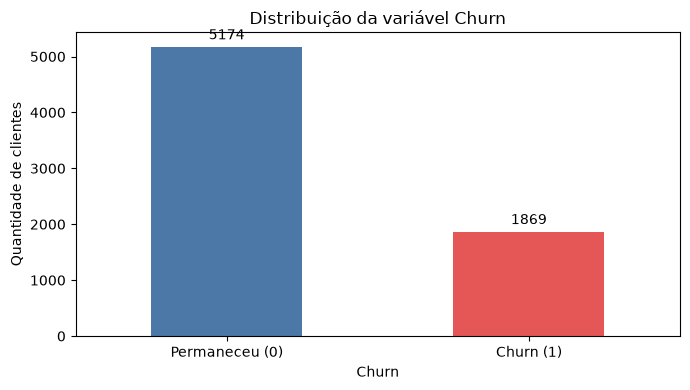

In [170]:
target_counts = (
    df["Churn Value"]
    .value_counts()
    .reindex([0, 1])
)

ax = target_counts.plot(
    kind="bar",
    color=["#4C78A8", "#E45756"],
    figsize=(7, 4),
)

ax.set_title("Distribuição da variável Churn")
ax.set_xlabel("Churn")
ax.set_ylabel("Quantidade de clientes")
ax.set_xticklabels([
    "Permaneceu (0)",
    "Churn (1)",
])
ax.tick_params(axis="x", rotation=0)

for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=3)

plt.tight_layout()
plt.show()

### 5.3. Interpretação

A classe `0` reúne **5.174 clientes (73,46%)**, enquanto a classe `1` possui **1.869 clientes (26,54%)**. Assim, existe predominância de clientes que não apresentaram churn.

A distribuição é desigual, mas a necessidade de técnicas de balanceamento não deve ser decidida apenas por esses percentuais. Essa decisão deverá considerar o desempenho dos modelos, especialmente na identificação da classe positiva.

Na futura divisão dos dados, será utilizada estratificação para preservar essa proporção nos conjuntos de treino e teste. A avaliação não deverá depender somente de acurácia, pois um modelo que favoreça a classe majoritária pode obter uma acurácia aparentemente alta e ainda detectar poucos clientes com churn. Serão consideradas métricas como:

- precision da classe positiva;
- recall da classe positiva;
- F1-score;
- ROC-AUC e PR-AUC;
- matriz de confusão.

Nenhuma técnica como SMOTE, oversampling ou undersampling será aplicada durante o EDA. Caso necessária, ela será aplicada exclusivamente ao conjunto de treino, evitando vazamento de dados.

### 5.4. Definição preliminar de features e target

In [171]:
columns_to_exclude = (
    [target_column]
    + identifier_columns
    + constant_columns
    + leakage_columns
    + redundant_columns
)

X_preliminary = df.drop(
    columns=columns_to_exclude
)

y = df[target_column].copy()

print(f"Dimensão preliminar de X: {X_preliminary.shape}")
print(f"Dimensão de y: {y.shape}")
print("Distribuição numérica do target:")

display(
    y.value_counts()
    .sort_index()
)

Dimensão preliminar de X: (7043, 24)
Dimensão de y: (7043,)
Distribuição numérica do target:


Churn Value
0    5174
1    1869
Name: count, dtype: int64

A definição acima é **preliminar** e serve para documentar a separação entre features e target. A decisão sobre `CLTV` e sobre quais variáveis geográficas permanecerão será tomada após validação de negócio e continuidade da análise exploratória.

## 6. Análise univariada

Objetivo: entender cada variável individualmente.

### 6.1. Variáveis numéricas

As principais variáveis numéricas relevantes são:

In [172]:
numeric_columns = [
    "Tenure Months",
    "Monthly Charges",
    "Total Charges",
    "CLTV",
]

In [173]:
df[numeric_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
Tenure Months,7043.0,32.371149,24.559481,0.00,9.00,29.000,55.0000,72.00
Monthly Charges,7043.0,64.761692,30.090047,18.25,35.50,70.350,89.8500,118.75
Total Charges,7032.0,2283.300441,2266.771362,18.80,401.45,1397.475,3794.7375,8684.80
CLTV,7043.0,4400.295755,1183.057152,2003.00,3469.00,4527.000,5380.5000,6500.00


`Tenure Months`: Grande dispersão no tempo de permanência

`Monthly Charges`: Valores distribuídos em uma faixa ampla

`Total Charges`: Distribuição assimétrica à direita

`CLTV`: Distribuição aparentemente mais centralizada

In [174]:
numeric_summary = df[numeric_columns].agg(
    ["mean", "median", "std", "min", "max", "skew"]
).T

numeric_summary

,mean,median,std,min,max,skew
Tenure Months,32.371149,29.000,24.559481,0.00,72.00,0.239540
Monthly Charges,64.761692,70.350,30.090047,18.25,118.75,-0.220524
Total Charges,2283.300441,1397.475,2266.771362,18.80,8684.80,0.961642
CLTV,4400.295755,4527.000,1183.057152,2003.00,6500.00,-0.311602


`Tenure Months`: apresenta leve assimetria positiva (skew = 0,24), mas seu histograma revela uma distribuição não uniforme, com concentrações nos primeiros meses e próximo do limite de 72 meses. Esse comportamento sugere a presença de grupos distintos de clientes, especialmente clientes recém-ingressos e clientes de longa permanência.

`Monthly Charges`: apresenta leve assimetria negativa (skew = -0,22), coerente com a média inferior à mediana. Entretanto, o histograma apresenta múltiplas concentrações, especialmente uma frequência elevada nos menores valores. Esse comportamento pode refletir diferentes combinações de serviços contratados pelos clientes.

`Total Charges`: apresenta assimetria positiva relevante (skew = 0,96). Há concentração nos valores menores e uma cauda longa em direção aos valores elevados. Esse comportamento é esperado para uma variável acumulada, pois clientes com maior tempo de permanência tendem a apresentar cobranças totais maiores.

`CLTV`: apresenta leve assimetria negativa (skew = -0,31), com maior concentração de clientes nos valores intermediários e elevados. Apesar do sinal negativo, a distribuição possui formato irregular e não deve ser considerada normal ou perfeitamente simétrica.

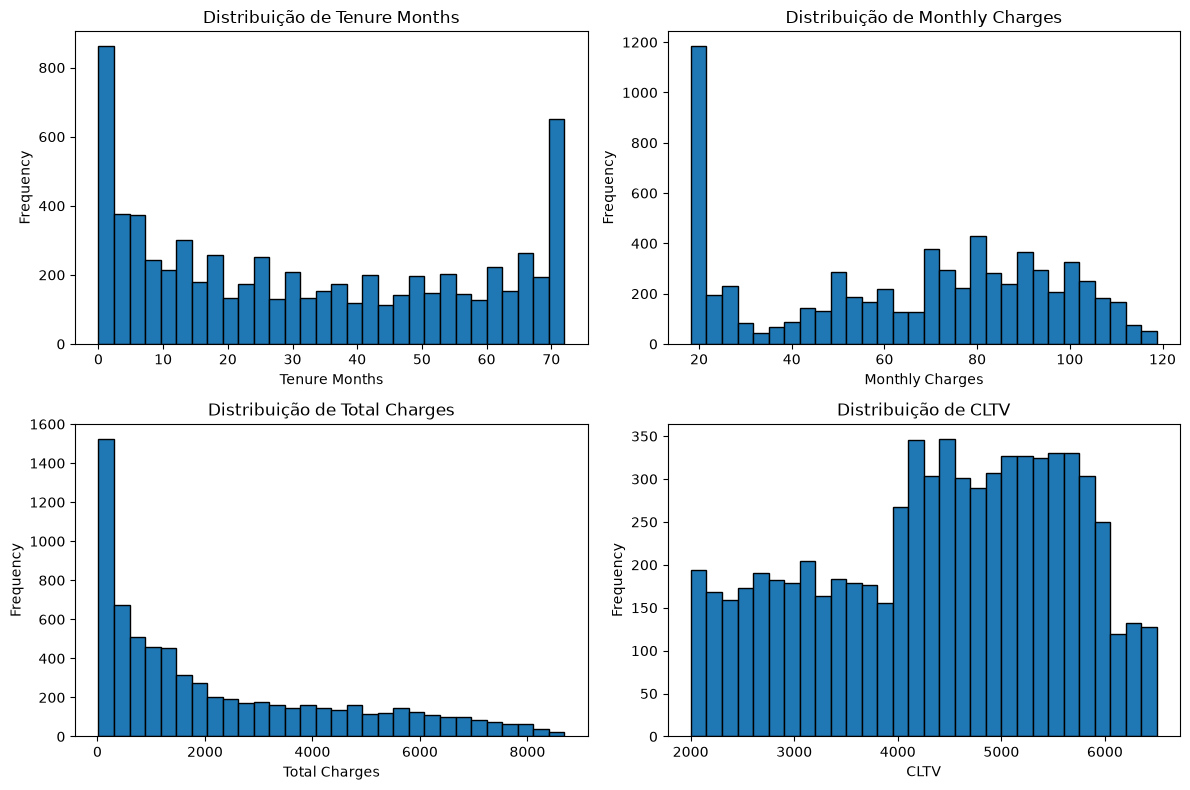

In [175]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for column, ax in zip(numeric_columns, axes.flatten()):
    df[column].plot(
        kind="hist",
        bins=30,
        ax=ax,
        edgecolor="black",
    )
    ax.set_title(f"Distribuição de {column}")
    ax.set_xlabel(column)

plt.tight_layout()
plt.show()

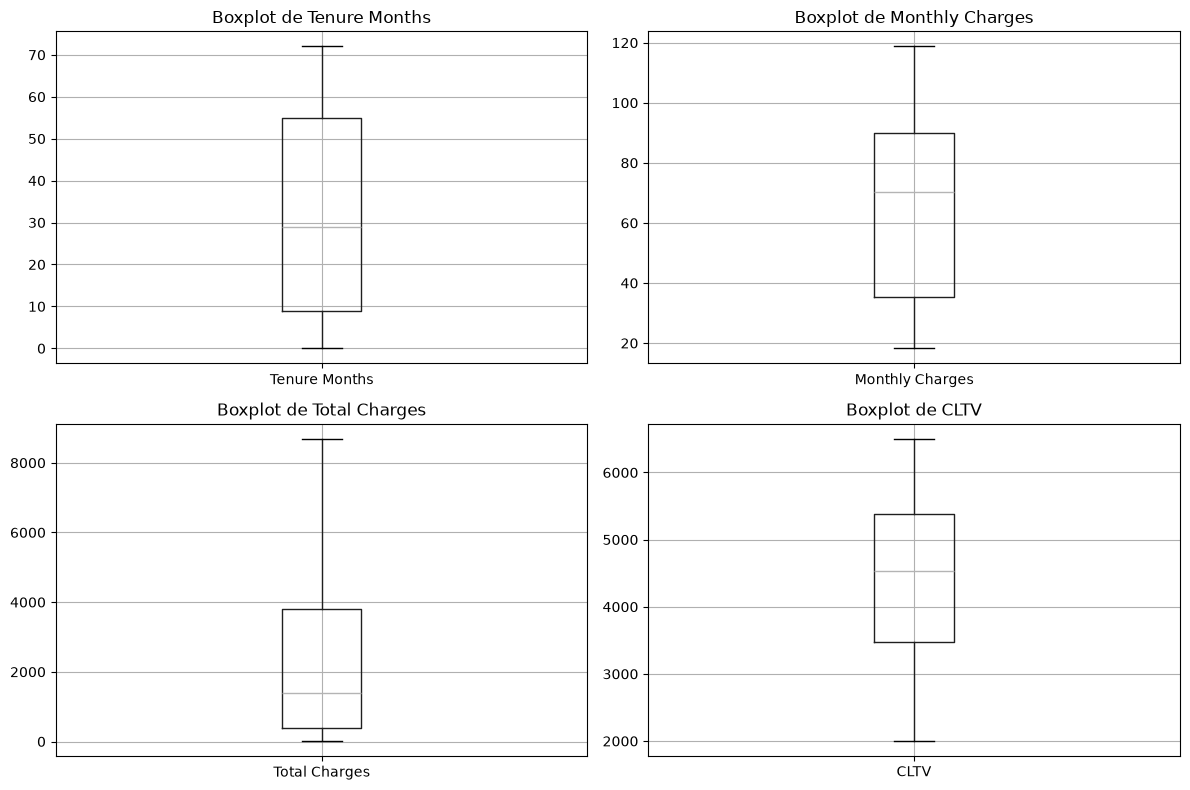

In [176]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for column, ax in zip(numeric_columns, axes.flatten()):
    df.boxplot(column=column, ax=ax)
    ax.set_title(f"Boxplot de {column}")

plt.tight_layout()
plt.show()

In [177]:
def iqr_outlier_summary(data, columns):
    rows = []

    for column in columns:
        series = data[column].dropna()

        q1 = series.quantile(0.25)
        q3 = series.quantile(0.75)
        iqr = q3 - q1

        lower_bound = q1 - 1.5 * iqr
        upper_bound = q3 + 1.5 * iqr

        outliers = series[
            (series < lower_bound)
            | (series > upper_bound)
        ]

        rows.append({
            "Variável": column,
            "Limite inferior": round(lower_bound, 2),
            "Limite superior": round(upper_bound, 2),
            "Quantidade": len(outliers),
            "Percentual (%)": round(
                len(outliers) / len(series) * 100,
                2,
            ),
        })

    return pd.DataFrame(rows)


iqr_outlier_summary(df, numeric_columns)

,Variável,Limite inferior,Limite superior,Quantidade,Percentual (%)
0,Tenure Months,-60.00,124.00,0,0.0
1,Monthly Charges,-46.02,171.38,0,0.0
2,Total Charges,-4688.48,8884.67,0,0.0
3,CLTV,601.75,8247.75,0,0.0


As variáveis numéricas apresentam escalas e distribuições diferentes. `Total Charges` possui maior assimetria, com média superior à mediana, comportamento consistente com uma variável de valor acumulado. 

`Tenure Months` apresenta grande dispersão, abrangendo desde clientes recém-ingressos até clientes com 72 meses de permanência. 

Embora as variáveis apresentem amplitudes e distribuições distintas, não foram identificados outliers pelo critério de 1,5 vez o intervalo interquartil. Os limites inferiores negativos apresentados são limites estatísticos teóricos e não representam valores negativos existentes no dataset.

### 6.2. Variáveis categóricas

In [178]:
categorical_columns = [
    "Gender",
    "Senior Citizen",
    "Partner",
    "Dependents",
    "Phone Service",
    "Multiple Lines",
    "Internet Service",
    "Online Security",
    "Online Backup",
    "Device Protection",
    "Tech Support",
    "Streaming TV",
    "Streaming Movies",
    "Contract",
    "Paperless Billing",
    "Payment Method",
]

In [179]:
def category_distribution(data, column):
    counts = data[column].value_counts(dropna=False)
    percentages = (
        data[column]
        .value_counts(dropna=False, normalize=True)
        .mul(100)
        .round(2)
    )

    return pd.DataFrame({
        "Quantidade": counts,
        "Percentual (%)": percentages,
    })

In [180]:
for column in categorical_columns:
    print(f"\n{column}")
    display(category_distribution(df, column))


Gender


,Quantidade,Percentual (%)
Gender,,
Male,3555,50.48
Female,3488,49.52



Senior Citizen


,Quantidade,Percentual (%)
Senior Citizen,,
No,5901,83.79
Yes,1142,16.21



Partner


...

,Quantidade,Percentual (%)
Contract,,
Month-to-month,3875,55.02
Two year,1695,24.07
One year,1473,20.91



Paperless Billing


,Quantidade,Percentual (%)
Paperless Billing,,
Yes,4171,59.22
No,2872,40.78



Payment Method


,Quantidade,Percentual (%)
Payment Method,,
Electronic check,2365,33.58
Mailed check,1612,22.89
Bank transfer (automatic),1544,21.92
Credit card (automatic),1522,21.61


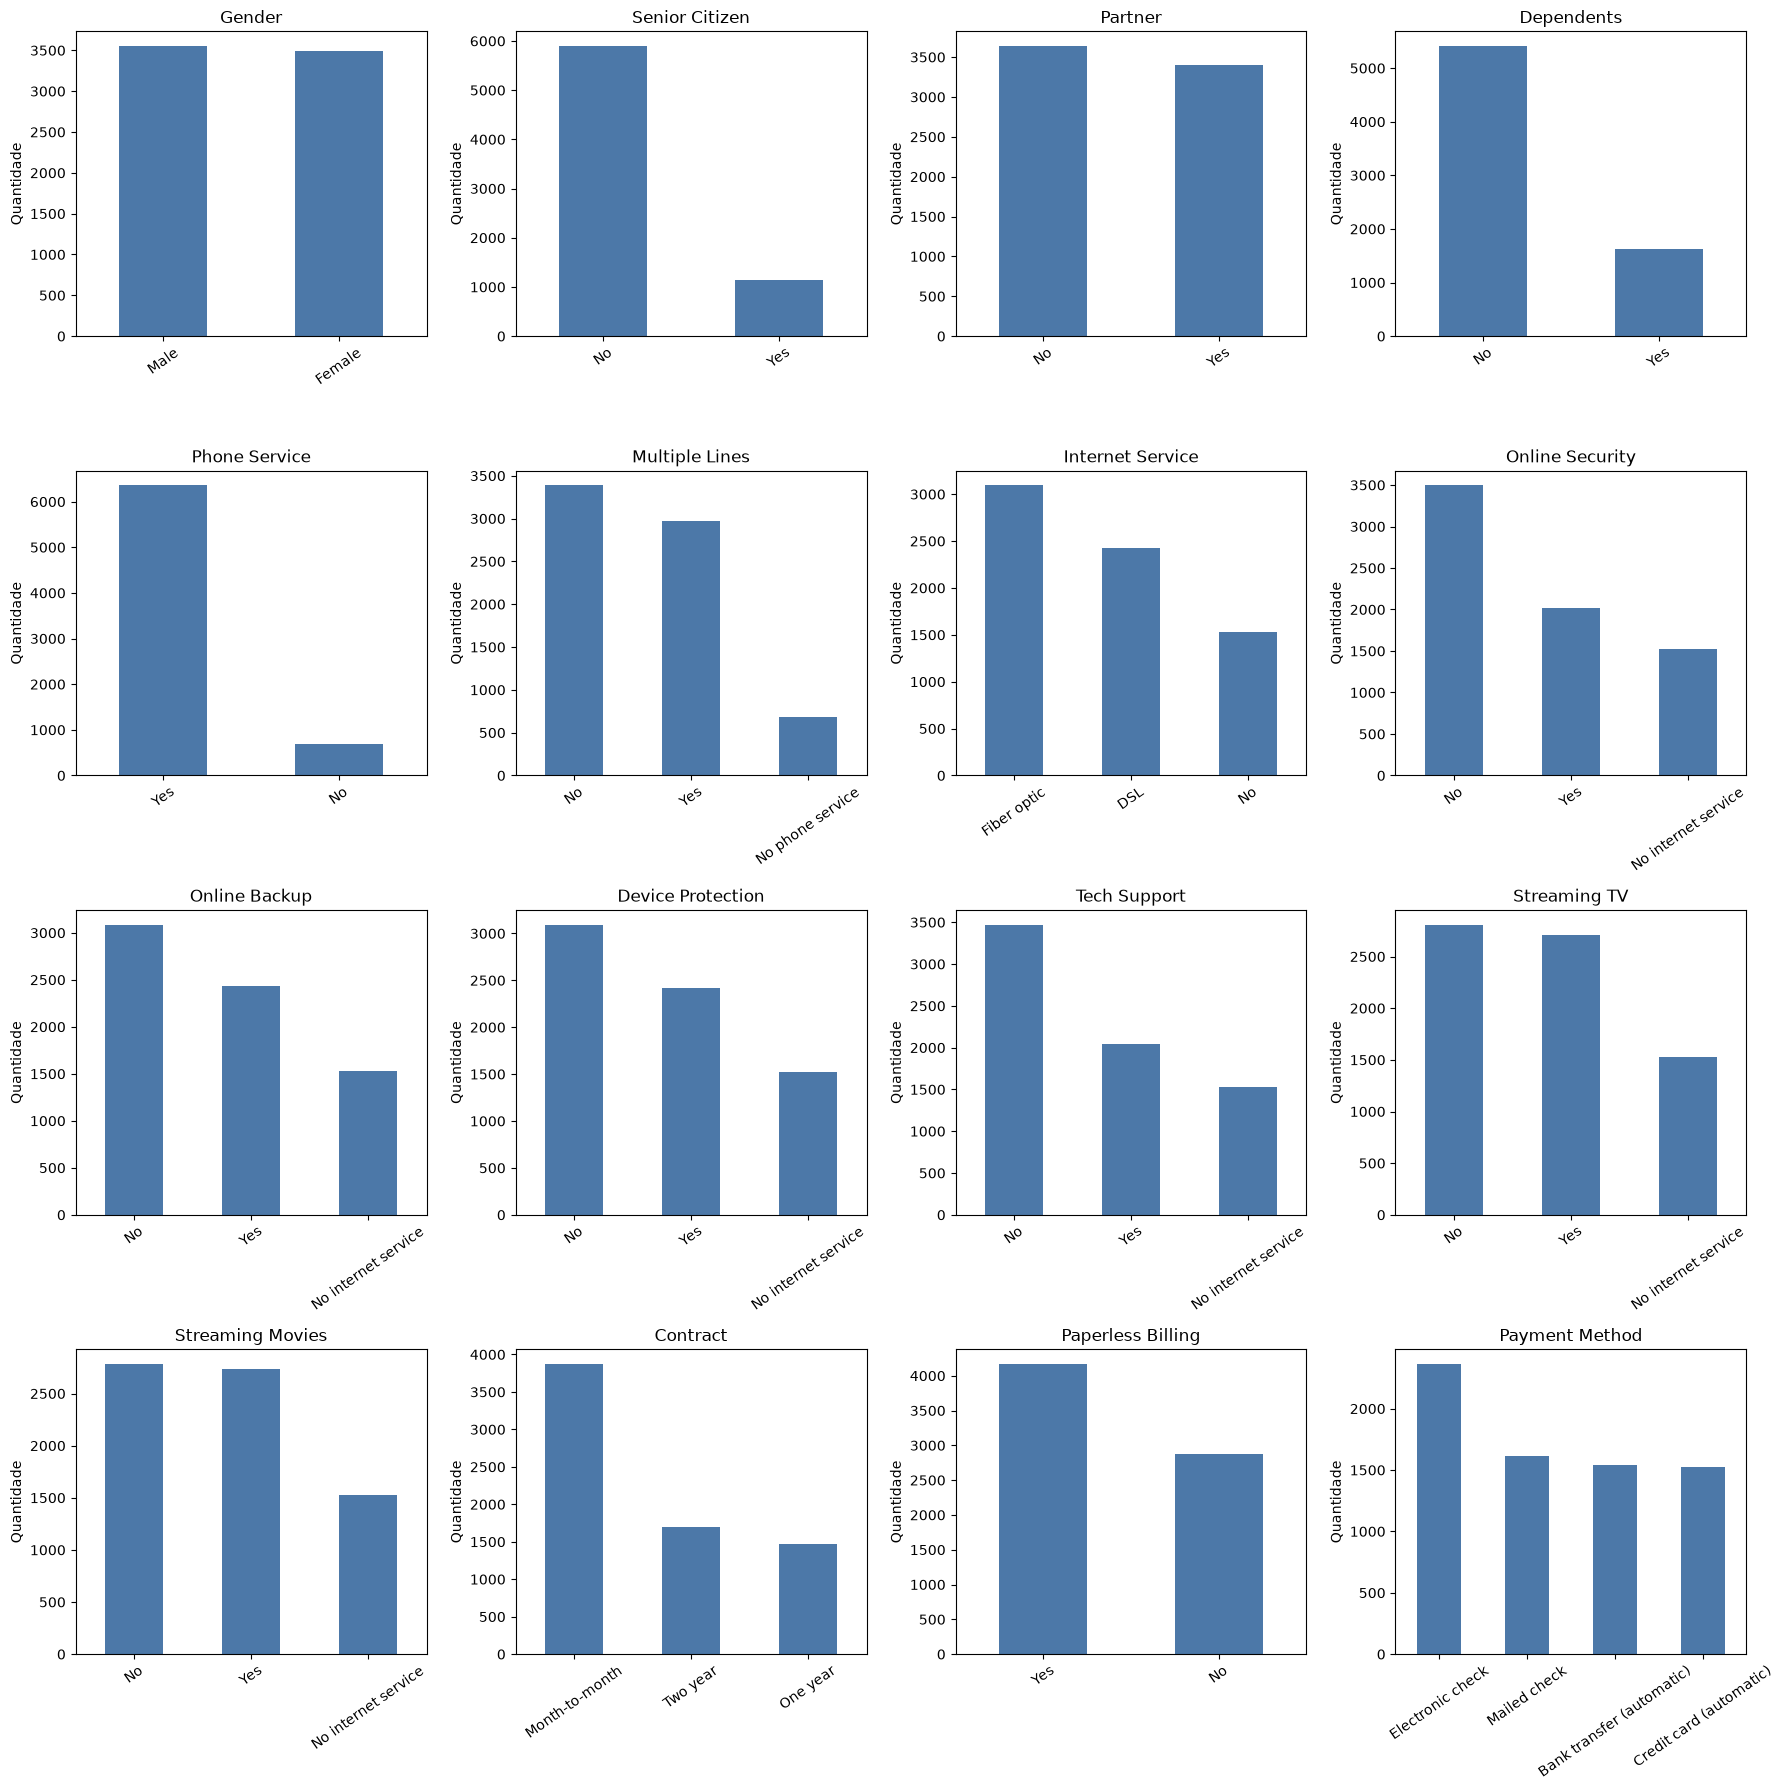

In [181]:
fig, axes = plt.subplots(4, 4, figsize=(18, 18))
axes = axes.flatten()

for column, ax in zip(categorical_columns, axes):
    counts = df[column].value_counts()

    counts.plot(
        kind="bar",
        ax=ax,
        color="#4C78A8",
    )

    ax.set_title(column)
    ax.set_xlabel("")
    ax.set_ylabel("Quantidade")
    ax.tick_params(axis="x", rotation=35)

plt.tight_layout()
plt.show()

As variáveis categóricas apresentam distribuições distintas. O gênero está aproximadamente equilibrado, enquanto variáveis como `Senior Citizen`, `Dependents` e `Phone Service` possuem categorias predominantes. O contrato mensal é o tipo mais frequente e o cheque eletrônico é a forma de pagamento mais utilizada. As categorias `No internet service` e `No phone service` possuem significado próprio e deverão ser preservadas durante a codificação.

## 7. Análise bivariada com o target

### 7.1. Numéricas × churn

In [182]:
df.groupby("Churn Value")[numeric_columns].agg(
    ["count", "mean", "median", "std"]
).T

Churn Value                       0            1
Tenure Months   count   5174.000000  1869.000000
                mean      37.569965    17.979133
                median    38.000000    10.000000
                std       24.113777    19.531123
Monthly Charges count   5174.000000  1869.000000
                mean      61.265124    74.441332
                median    64.425000    79.650000
                std       31.092648    24.666053
Total Charges   count   5163.000000  1869.000000
                mean    2555.344141  1531.796094
                median  1683.600000   703.550000
                std     2329.456984  1890.822994
CLTV            count   5174.000000  1869.000000
                mean    4490.921337  4149.414660
                median  4620.000000  4238.000000
                std     1167.703198  1189.370707

`Tenure Months`:
* mediana sem churn: 38 meses;
* mediana com churn: 10 meses;
* média sem churn: 37,57 meses;
* média com churn: 17,98 meses.

Clientes que apresentaram churn possuem tempo de permanência consideravelmente menor. Esse é um dos sinais mais relevantes encontrados no EDA, sugerindo maior risco de saída durante os períodos iniciais do relacionamento.

`Monthly Charges`:
* média sem churn: 61,27;
* média com churn: 74,44;
* mediana sem churn: 64,43;
* mediana com churn: 79,65.


Clientes com churn apresentam cobranças mensais mais elevadas, indicando uma associação positiva entre valor mensal e saída.

`Total Charges`:
* mediana sem churn: 1.683,60;
* mediana com churn: 703,55.

Clientes com churn apresentam menor cobrança total acumulada, provavelmente porque permanecem menos tempo na empresa. Portanto, essa relação deve ser analisada em conjunto com Tenure Months.

`CLTV`:
* média sem churn: 4.490,92;
* média com churn: 4.149,41.

O CLTV é menor entre clientes que apresentaram churn. Entretanto, sua utilização como feature depende de confirmar que o valor estaria disponível no instante real da previsão e que não incorpora informações futuras.

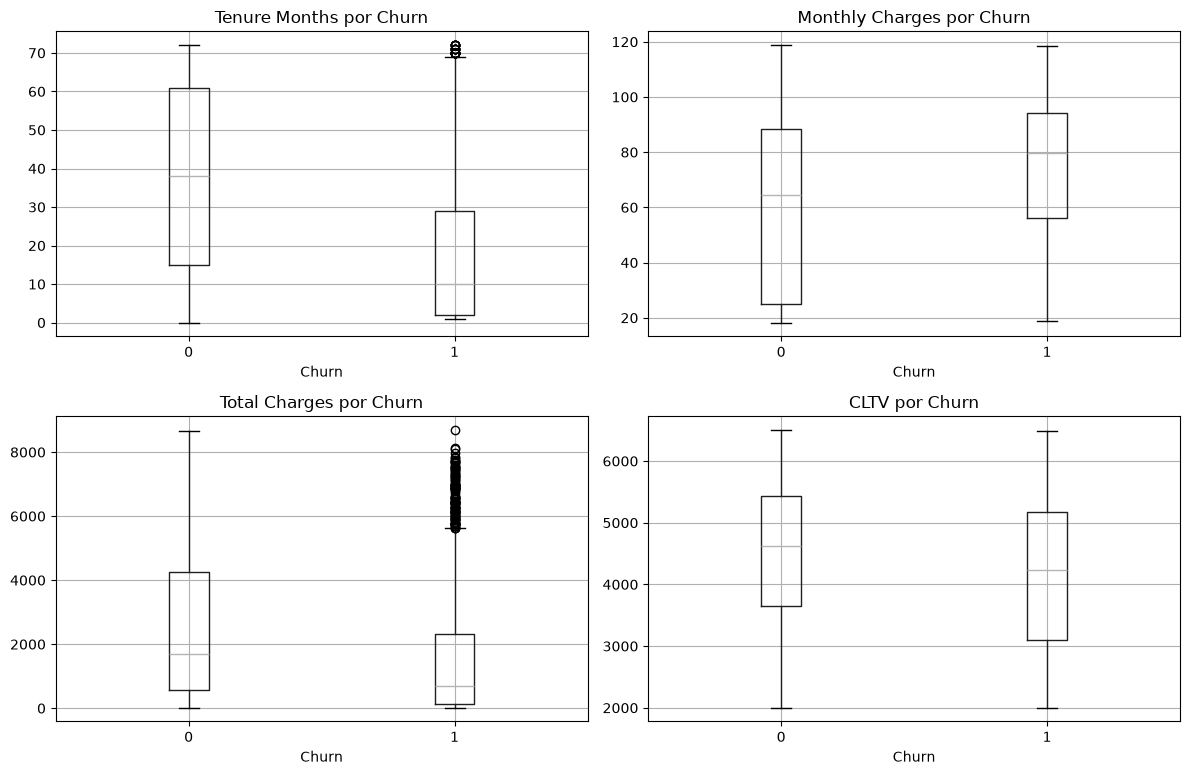

In [183]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for column, ax in zip(numeric_columns, axes.flatten()):
    df.boxplot(
        column=column,
        by="Churn Value",
        ax=ax,
    )
    ax.set_title(f"{column} por Churn")
    ax.set_xlabel("Churn")

plt.suptitle("")
plt.tight_layout()
plt.show()

### 7.2. Categóricas × churn

In [184]:
def churn_rate_by_category(data, column):
    result = (
        data.groupby(column, dropna=False)
        .agg(
            Clientes=("Churn Value", "size"),
            Churns=("Churn Value", "sum"),
            Taxa_Churn=("Churn Value", "mean"),
        )
        .sort_values("Taxa_Churn", ascending=False)
    )

    result["Taxa_Churn (%)"] = (
        result["Taxa_Churn"] * 100
    ).round(2)

    return result.drop(columns="Taxa_Churn")

In [185]:
churn_rate_by_category(df, "Contract")

,Clientes,Churns,Taxa_Churn (%)
Contract,,,
Month-to-month,3875,1655,42.71
One year,1473,166,11.27
Two year,1695,48,2.83


O contrato mensal apresenta taxa de churn muito superior aos contratos de maior duração. Essa é uma das associações mais fortes observadas no dataset.

In [186]:
def plot_churn_rate(data, column, ax):
    rates = (
        data.groupby(column)["Churn Value"]
        .mean()
        .mul(100)
        .sort_values(ascending=False)
    )

    rates.plot(
        kind="bar",
        ax=ax,  
        color="#E45756",
    )

    ax.set_title(f"Taxa de churn por {column}")
    ax.set_xlabel(column)
    ax.set_ylabel("Taxa de churn (%)")
    ax.tick_params(axis="x", rotation=30)

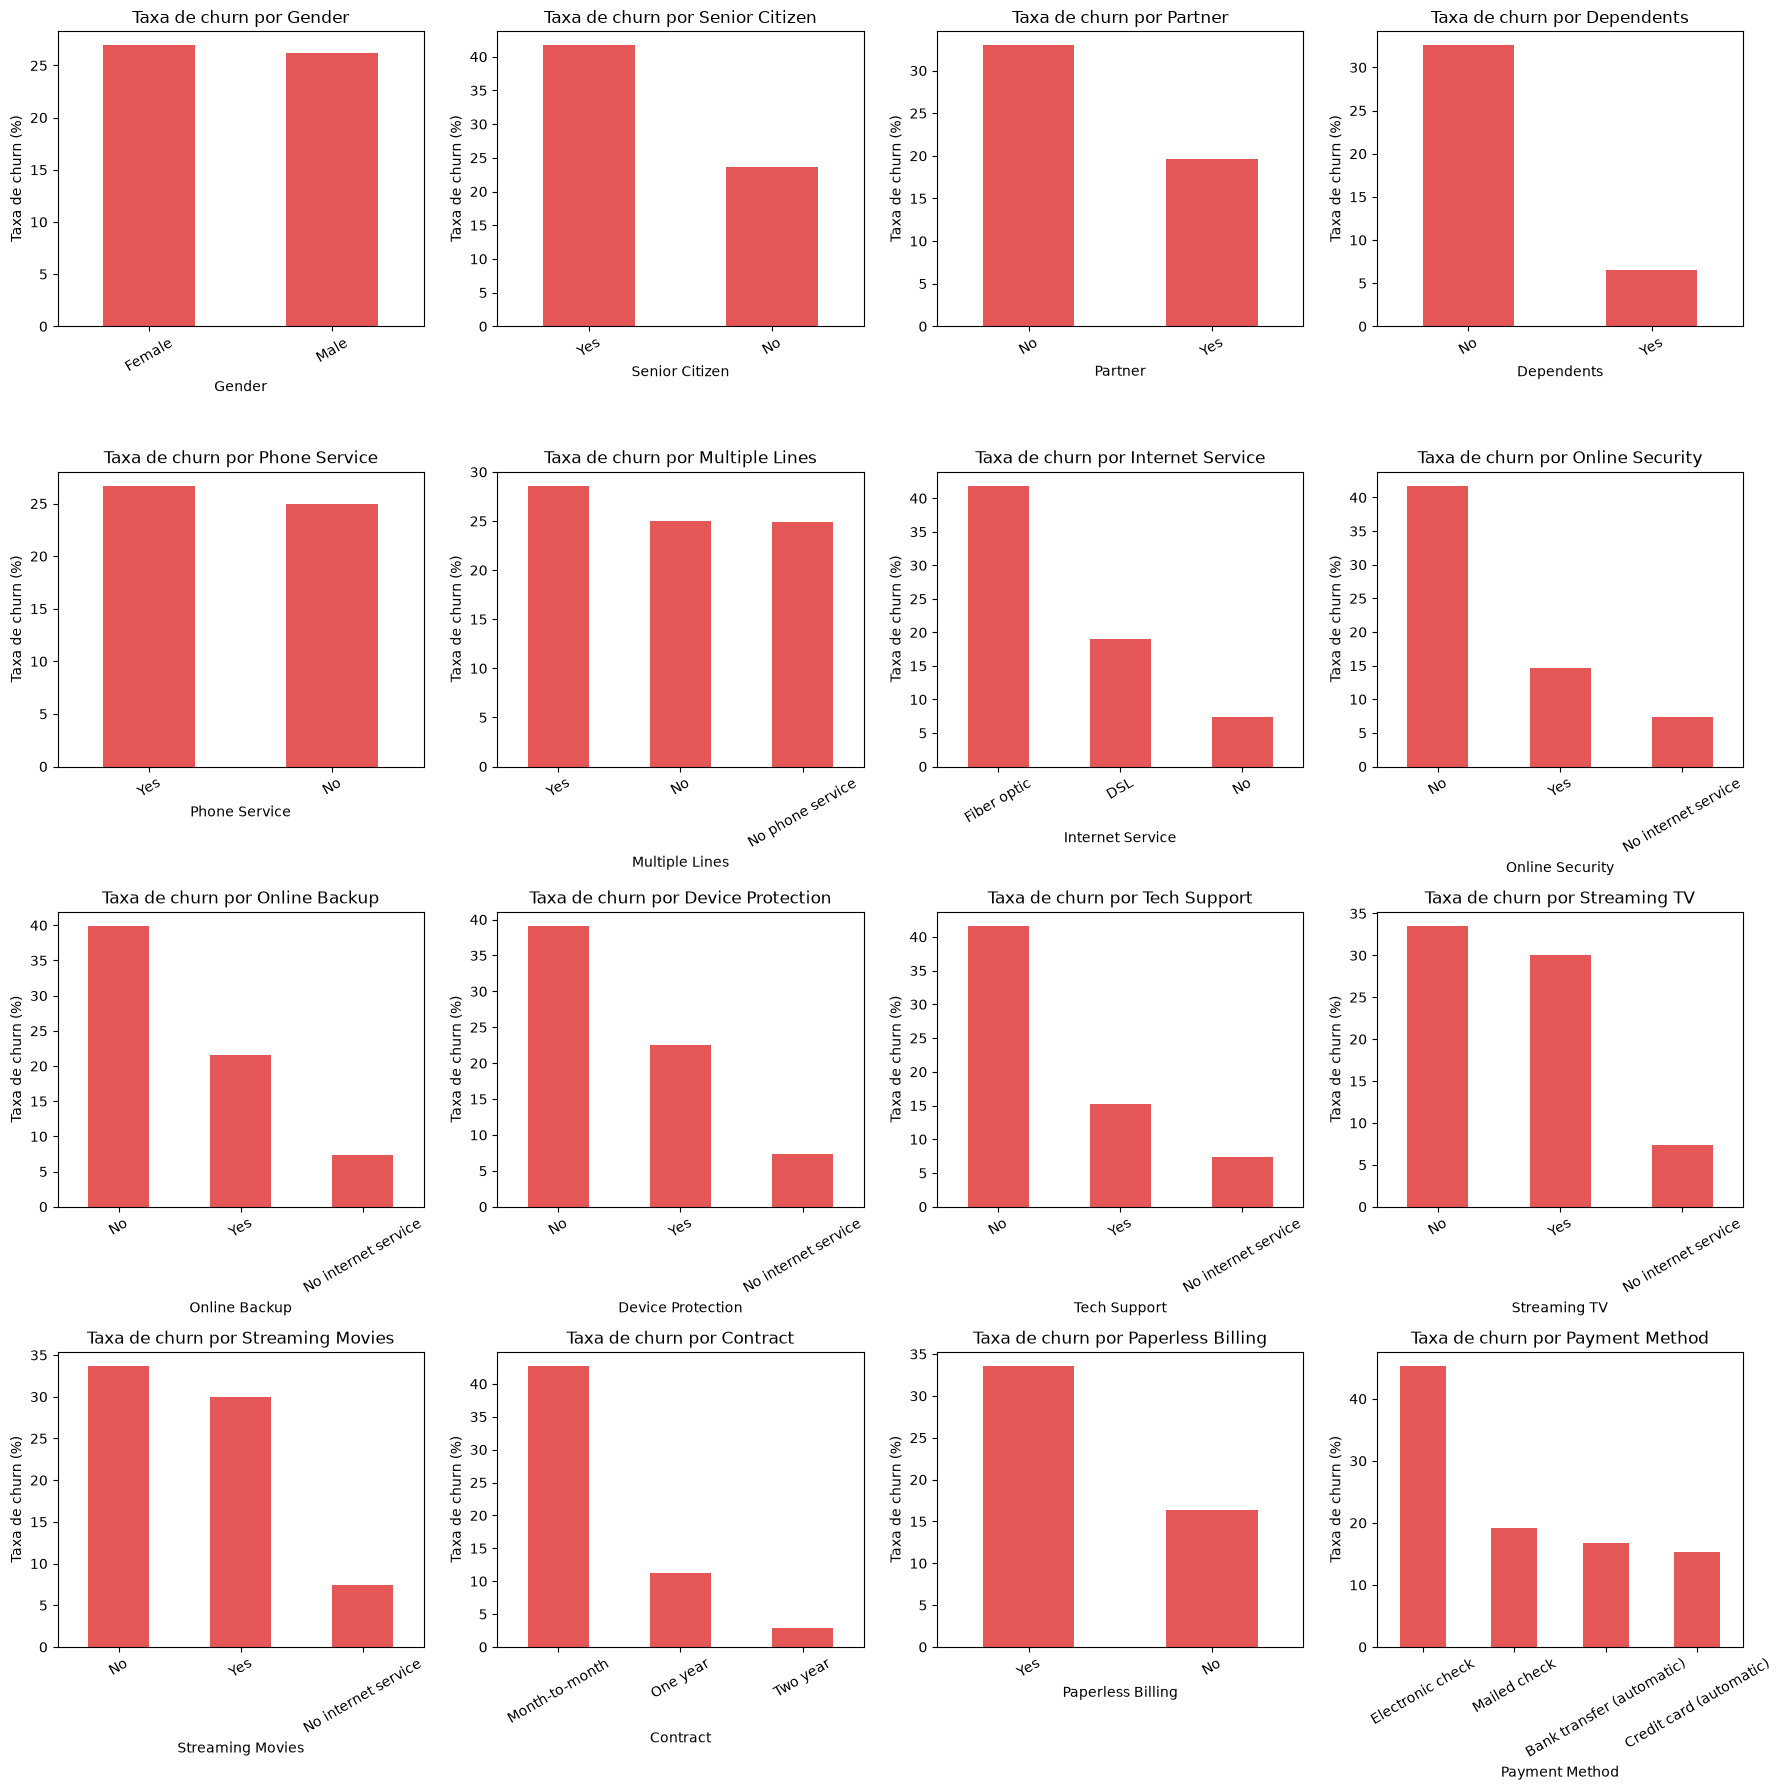

In [187]:
fig, axes = plt.subplots(4, 4, figsize=(18, 18))

for column, ax in zip(categorical_columns, axes.flatten()):
    plot_churn_rate(df, column, ax)

plt.tight_layout()
plt.show()

Clientes com fibra óptica apresentam maior taxa de churn. Isso não demonstra que a fibra causa churn; preço, perfil do cliente, qualidade percebida e serviços associados podem explicar parte dessa relação.

Clientes sem segurança online ou suporte técnico apresentam taxas de churn consideravelmente maiores.

O cheque eletrônico apresenta uma taxa de churn substancialmente superior às demais formas de pagamento.

Gênero e serviço telefônico isoladamente apresentam pouca diferença na taxa de churn, indicando baixo poder discriminativo aparente em análises individuais.

## 8. Relações entre variáveis

### 8.1. Correlação numérica

In [188]:
correlation_columns = [
    "Tenure Months",
    "Monthly Charges",
    "Total Charges",
    "CLTV",
    "Churn Value",
]

correlation_matrix = (
    df[correlation_columns]
    .corr()
    .round(2)
)

correlation_matrix

,Tenure Months,Monthly Charges,Total Charges,CLTV,Churn Value
Tenure Months,1.00,0.25,0.83,0.40,-0.35
Monthly Charges,0.25,1.00,0.65,0.10,0.19
Total Charges,0.83,0.65,1.00,0.34,-0.20
CLTV,0.40,0.10,0.34,1.00,-0.13
Churn Value,-0.35,0.19,-0.20,-0.13,1.00


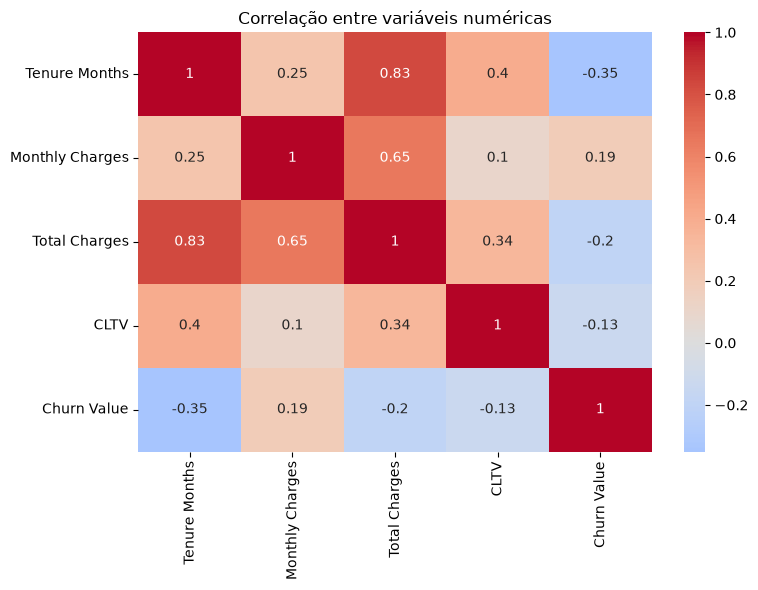

In [189]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    center=0,
)

plt.title("Correlação entre variáveis numéricas")
plt.tight_layout()
plt.show()

In [190]:
df[[
    "Tenure Months",
    "Monthly Charges",
    "Total Charges",
]].corr()

,Tenure Months,Monthly Charges,Total Charges
Tenure Months,1.00000,0.247900,0.825880
Monthly Charges,0.24790,1.000000,0.651065
Total Charges,0.82588,0.651065,1.000000


Existe forte correlação positiva entre `Tenure Months` e `Total Charges`, comportamento esperado porque o total cobrado se acumula ao longo do relacionamento. Isso indica possível redundância ou multicolinearidade, que deverá ser considerada especialmente em modelos lineares.

A correlação negativa entre permanência e churn indica que clientes antigos apresentam menor ocorrência de saída. A cobrança mensal possui correlação positiva com churn, enquanto o total acumulado possui correlação negativa, provavelmente influenciada pela permanência.

### 8.2. Relação entre permanência, cobrança e churn

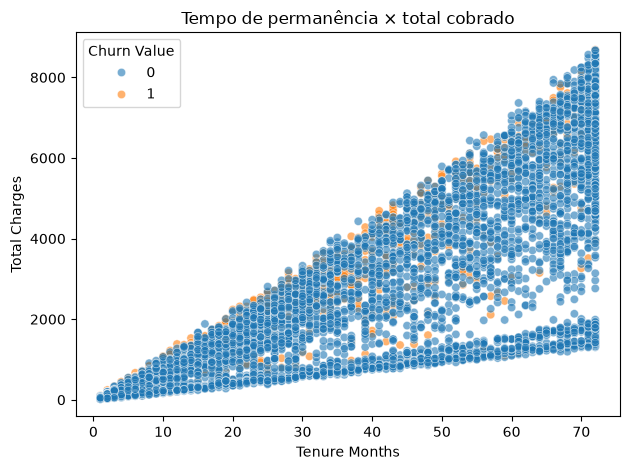

In [191]:
sns.scatterplot(
    data=df,
    x="Tenure Months",
    y="Total Charges",
    hue="Churn Value",
    alpha=0.6,
)

plt.title("Tempo de permanência × total cobrado")
plt.tight_layout()
plt.show()

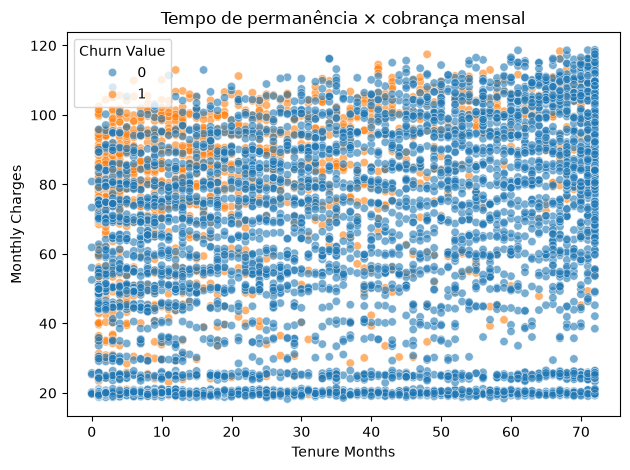

In [192]:
sns.scatterplot(
    data=df,
    x="Tenure Months",
    y="Monthly Charges",
    hue="Churn Value",
    alpha=0.6,
)

plt.title("Tempo de permanência × cobrança mensal")
plt.tight_layout()
plt.show()

## 9. Validação de consistência

Total cobrado versus permanência

In [193]:
df[
    (df["Tenure Months"] == 0)
    & (df["Total Charges"].notna())
][[
    "Tenure Months",
    "Monthly Charges",
    "Total Charges",
]]

,Tenure Months,Monthly Charges,Total Charges


In [194]:
internet_addons = [
    "Online Security",
    "Online Backup",
    "Device Protection",
    "Tech Support",
    "Streaming TV",
    "Streaming Movies",
]

for column in internet_addons:
    invalid = df[
        (df["Internet Service"] == "No")
        & (df[column] != "No internet service")
    ]

    print(column, len(invalid))

Online Security 0
Online Backup 0
Device Protection 0
Tech Support 0
Streaming TV 0
Streaming Movies 0


In [195]:
invalid_phone = df[
    (df["Phone Service"] == "No")
    & (df["Multiple Lines"] != "No phone service")
]

print(f"Inconsistências de telefonia: {len(invalid_phone)}")

Inconsistências de telefonia: 0


Clientes com zero meses não possuem `Total Charges`;

Clientes sem internet apresentam `No internet service` nos adicionais;

Clientes sem telefonia apresentam `No phone service` em múltiplas linhas.

## 10. Síntese dos insights

A análise exploratória identificou que 26,54% dos clientes apresentaram churn. Embora exista predominância da classe negativa, o desbalanceamento não é extremo e sua influência deverá ser avaliada durante a modelagem por meio de métricas voltadas à classe positiva.

Entre as variáveis numéricas, `Tenure Months` apresentou a diferença mais relevante entre as classes. Clientes que deixaram a empresa possuem mediana de permanência de 10 meses, enquanto clientes que permaneceram apresentam mediana de 38 meses. Os clientes com churn também possuem cobrança mensal mais elevada, com média de 74,44, contra 61,27 entre os demais.

Nas variáveis categóricas, as maiores taxas de churn foram observadas entre clientes com contrato mensal, internet por fibra óptica, pagamento por cheque eletrônico, ausência de segurança online e ausência de suporte técnico. Clientes idosos, sem parceiro ou sem dependentes também apresentaram taxas superiores.

Gênero, serviço telefônico e múltiplas linhas apresentaram diferenças menores quando analisados isoladamente. Isso indica menor poder discriminativo univariado, embora essas variáveis ainda possam contribuir por meio de interações com outras características.

Foi identificada forte correlação entre tempo de permanência e cobrança total acumulada. Essa relação é coerente com o significado das variáveis, mas pode gerar redundância, especialmente em modelos lineares.

Não foram encontradas inconsistências entre a contratação dos serviços principais e os respectivos serviços adicionais. Os valores ausentes de `Total Charges` estão associados a clientes com zero meses de permanência, enquanto as ausências de `Churn Reason` são estruturais.

As colunas `Churn Label`, `Churn Score` e `Churn Reason` serão excluídas das features por causarem vazamento do target. As colunas constantes e identificadoras também serão removidas. A utilização de `CLTV` dependerá da validação de sua disponibilidade no momento real da previsão.

Os resultados encontrados representam associações observadas no dataset e não permitem afirmar relações causais.

| Tipo          | Colunas                                      | Decisão                          |
| ------------- | -------------------------------------------- | -------------------------------- |
| Target        | `Churn Value`                                | Manter como está                 |
| Identificador | `CustomerID`                                 | Remover das features             |
| Constantes    | `Count`, `Country`, `State`                  | Remover                          |
| Vazamento     | `Churn Label`, `Churn Score`, `Churn Reason` | Remover                          |
| Redundância   | `Lat Long`                                   | Remover                          |
| Ausentes      | `Total Charges`                              | Tratar após divisão              |
| Numéricas     | permanência e cobranças                      | Avaliar escala                   |
| Categóricas   | serviços, contrato e pagamento               | Aplicar encoding                 |
| Pendente      | `CLTV`                                       | Validar disponibilidade temporal |
